# Size sweep: MSE and MAE against reservoir size

Plots the scores saved by `sweep.py` against the number of qubits (quantum reservoir) and the number of nodes (classical reservoir), for the Adam and ridge readouts. The dashed line is a linear model on the current observation, for reference.

Keep this notebook in `src/` and run `sweep.py` first. The figure is also saved as `results/sweep/size_sweep.png`.

In [1]:
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

RESULTS_PATH = Path("results/sweep/results.json")   # written by sweep.py; this notebook sits in src/
SPLIT = "test"                                      # "train", "validation" or "test"

results = json.loads(RESULTS_PATH.read_text())

def curve(model, size_key, readout, metric):
    # score against size for one model and readout (averaged if a size was run more than once, e.g. over seeds)
    runs = [r for r in results.values() if r.get("model") == model and r["readout"] == readout]
    sizes = sorted({r["config"][size_key] for r in runs})
    return sizes, [np.mean([r[SPLIT][metric] for r in runs if r["config"][size_key] == size]) for size in sizes]

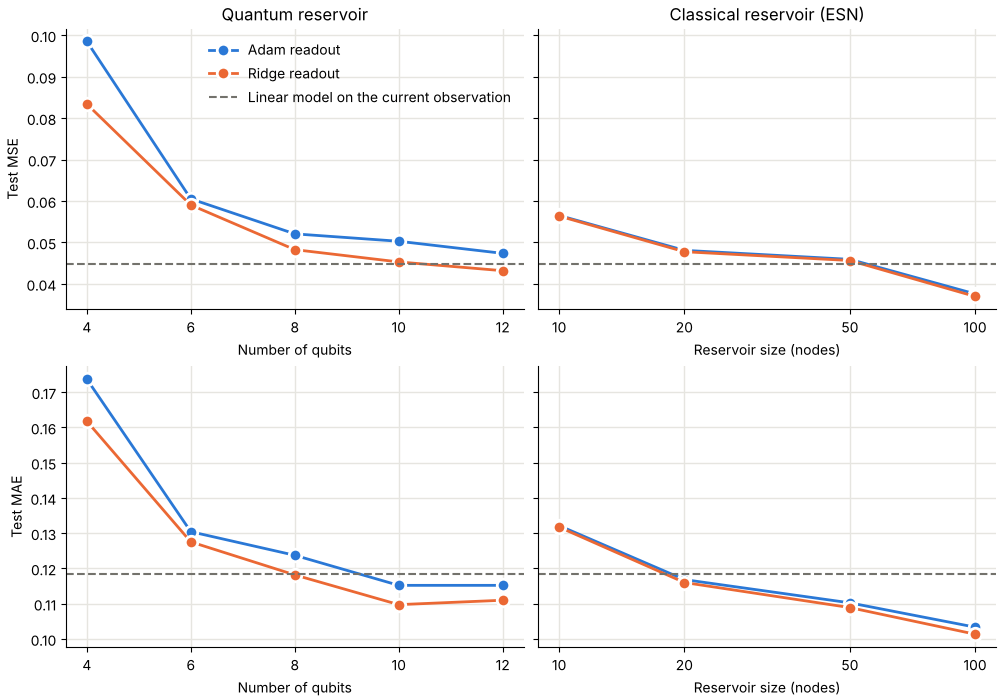

In [2]:
MODELS = [("quantum", "num_qubits", "Number of qubits", "Quantum reservoir"),
          ("esn", "reservoir_size", "Reservoir size (nodes)", "Classical reservoir (ESN)")]
METRICS = [("loss", "MSE"), ("mae", "MAE")]
READOUTS = {"adam": ("Adam readout", "#2a78d6"), "ridge": ("Ridge readout", "#eb6834")}

fig, axes = plt.subplots(2, 2, figsize=(10, 7), sharey="row", constrained_layout=True)
for row, (metric, metric_name) in enumerate(METRICS):
    for ax, (model, size_key, xlabel, title) in zip(axes[row], MODELS):
        for readout, (label, color) in READOUTS.items():
            sizes, scores = curve(model, size_key, readout, metric)
            ax.plot(sizes, scores, "o-", color=color, linewidth=2, markersize=9, markeredgecolor="white",
                    markeredgewidth=2, label=label)
        ax.axhline(results["linear_on_observation"][SPLIT][metric], color="#73726c", linestyle="--", linewidth=1.5,
                   label="Linear model on the current observation")
        if model == "esn":
            ax.set_xscale("log")
        ax.set_xticks(sizes, [str(size) for size in sizes])
        ax.minorticks_off()
        ax.set_xlabel(xlabel)
        ax.grid(color="#e6e5e0", linewidth=1)
        ax.spines[["top", "right"]].set_visible(False)
        if row == 0:
            ax.set_title(title)
    axes[row, 0].set_ylabel(f"{SPLIT.capitalize()} {metric_name}")
axes[0, 0].legend(frameon=False)
fig.savefig(RESULTS_PATH.with_name("size_sweep.png"), dpi=200)
plt.show()